# QualiScan — détection des défauts industriels

**Simulation pédagogique : données synthétiques.**

24 000 pièces sont mesurées dans 480 lots de fabrication. Six dimensions physiques et une étiquette de défaut sont disponibles. Certains relevés sont absents ou invalides. Les pièces d’un même lot partagent une dérive ; les erreurs de détection ont des coûts asymétriques.

## Objectif et démarche

Choisir un seuil sur validation, quantifier le coût d’erreurs sur un test indépendant et dimensionner la charge d’expertise humaine.

- Les partitions train/validation/test sont-elles disjointes au niveau des lots ? Les imputations et standardisations sont-elles apprises uniquement sur l’entraînement ?
- Comment la logistique se comporte-t-elle en validation croisée groupée et face à une forêt comparatrice ?
- Quel seuil minimise le coût 20×FN+FP sur validation et quelles erreurs produit-il sur le test ? Que changerait un seuil 0,50 ?
- Combien de pièces doivent être inspectées manuellement par millier traité et quelle est la précision de cette file ?
- Une régression peut-elle prédire l’épaisseur manquante sans utiliser l’étiquette ? Le clustering sépare-t-il réellement les classes et quelles limites montrent les scores ?

Exécuter les cellules dans l’ordre. Les sources synthétiques sont régénérées avec une graine fixe ; les données réelles éventuelles nécessiteraient une étape de chargement distincte.

In [1]:
from pathlib import Path
import os, sqlite3, textwrap
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

# Retrouver le dossier du projet depuis sa racine ou le dossier notebooks.
ROOT = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'data/raw').is_dir())
RAW, CLEAN, OUT, REPORT = [ROOT / p for p in ['data/raw', 'data/processed', 'analysis', 'reports']]
for directory in [RAW, CLEAN, OUT, REPORT, ROOT / 'docs']:
    directory.mkdir(parents=True, exist_ok=True)
RNG = np.random.default_rng(20261010)
AUDIT, DICT, FIGS, SECTIONS = [], [], [], []
plt.rcParams.update({'figure.figsize': (10, 4.8), 'axes.spines.top': False, 'axes.spines.right': False})


## Fonctions de qualité et de visualisation

Ces fonctions centralisent les exports CSV, la traçabilité des exclusions et les légendes des graphiques. Le bilan brut = doublons + rejets + propre est vérifié par assertion.

In [2]:
DEFAULT_UNITS = {'region': 'Région fictive', 'nom': 'Nom fictif', 'population': 'personnes', 'surface': 'm²', 'pieces': 'nombre de pièces', 'type': 'type de bien', 'date': 'ISO yyyy-MM-dd', 'prix': 'EUR/unité (transaction : EUR/bien)', 'nature': 'principal/annexe', 'categorie': 'catégorie produit', 'annee': 'année civile', 'kcal_kg': 'kcal/kg', 'production_t': 'tonnes/an', 'importations_t': 'tonnes/an', 'exportations_t': 'tonnes/an', 'variation_stock_t': 'tonnes/an, signe positif = apport au bilan', 'pertes_t': 'tonnes/an', 'alimentation_animale_t': 'tonnes/an', 'autres_usages_t': 'tonnes/an', 'cout': 'EUR/unité', 'stock_initial': 'unités, proxy de stock moyen', 'sku': 'identifiant web fictif', 'quantite': 'unités', 'remise': 'fraction, 0.10 = 10 %', 'retour': 'unités retournées', 'age': 'années', 'anciennete': 'années', 'segment': 'particulier/professionnel fictif', 'sexe': 'F/H, catégories simplifiées de la simulation', 'niveau': 'niveau de poste fictif', 'metier': 'famille métier fictive', 'site': 'site fictif', 'quotite': 'ETP contractuel, 0 < x <= 1', 'salaire_annuel_verse': 'EUR/an au temps contractuel', 'pays': 'territoire fictif', 'zone': 'Rural/Urbain', 'acces_sur_pct': 'pourcentage 0–100', 'budget_millions_eur': 'millions EUR', 'cout_beneficiaire_eur': 'EUR/personne', 'pib_habitant': 'USD fictifs/personne/an', 'conso_kg_hab': 'kg/personne/an', 'risque_logistique': 'score 0–100, élevé défavorable', 'croissance_pct': 'points de pourcentage annuel', 'est_defaut': '1=faux simulé, 0=conforme simulé', 'longueur': 'mm', 'largeur_gauche': 'mm', 'largeur_droite': 'mm', 'epaisseur_haute': 'mm', 'epaisseur_basse': 'mm', 'entraxe': 'mm'}

def csv(df, file):
    df.to_csv(file, index=False, sep=';', encoding='utf-8-sig', float_format='%.8f')

def source(df, name, grain, units=None):
    csv(df, RAW / (name + '.csv'))
    for c in df:
        DICT.append({'table': name, 'grain': grain, 'colonne': c, 'type': str(df[c].dtype), 'unite_ou_sens': (units or {}).get(c, DEFAULT_UNITS.get(c, 'Identifiant fictif' if c.endswith('_id') else 'Voir énoncé et code de génération')), 'manquants': int(df[c].isna().sum())})

def clean(df, key, mask, name):
    dup = df.duplicated(key, keep='first')
    u = df.loc[~dup].copy()
    valid = mask(u).fillna(False)
    rejects = u.loc[~valid].copy()
    rejects['motif'] = 'Contrat de validation violé : voir les cellules de nettoyage du notebook'
    csv(df.loc[dup], OUT / (name + '_doublons.csv'))
    csv(rejects, OUT / (name + '_rejets.csv'))
    r = u.loc[valid].copy()
    AUDIT.append({'table': name, 'brut': len(df), 'doublons': int(dup.sum()), 'rejets': len(rejects), 'propre': len(r)})
    csv(r, CLEAN / (name + '.csv'))
    assert len(df) == int(dup.sum()) + len(rejects) + len(r)
    assert not r.duplicated(key).any()
    return r

FIGURE_LABELS = {'flux_stations': ('Solde des flux par station', 'Identifiant de station', 'Arrivées moins départs, locations'), 'ca_maintenance': ('Recettes et maintenance mensuelles', 'Mois', 'EUR'), 'prix_m2_annuel': ('Prix au m² — territoires fictifs', 'Année', 'Médiane des médianes communales, EUR/m²'), 'erreurs_prediction': ('Erreurs du modèle sur 2025', 'Prédiction moins prix réel, EUR', 'Nombre de ventes'), 'disponibilite_ponderee': ('Disponibilité calorique — bilans complets', 'Année', 'kcal/jour/personne, pondéré par population'), 'dependance_et_disponibilite': ('Dépendance aux importations et disponibilité', 'Importations / (production + importations)', 'Disponibilité, kcal/jour/personne'), 'distribution_prix': ('Distribution des prix catalogue', 'Logarithme naturel du prix en EUR', 'Nombre de références'), 'pareto_ca': ('Concentration du chiffre d’affaires', 'Fraction des références, par CA décroissant', 'Fraction cumulée du CA'), 'ca_et_marge_mensuels': ('Ventes et marge commerciale', 'Mois', 'EUR'), 'decomposition': ('Série mensuelle et décomposition STL', 'Mois', 'EUR'), 'validation_prevision': ('Prévision — six mois de test chronologique', 'Mois', 'Chiffre d’affaires net, EUR'), 'retention_cohortes': ('Rétention par cohorte — cellules futures non observées', 'Ancienneté en mois', 'Cohorte, ordre chronologique'), 'salaires_etp': ('Distribution des salaires normalisés ETP', 'Catégorie de sexe simulée', 'EUR/an équivalent temps plein'), 'ecarts_brut_ajuste': ('Écart salarial descriptif', 'Méthode', 'Écart en %, référence masculine'), 'besoin_regional': ('Population sans accès — données observées', 'Année', '% de la population observée'), 'stabilite_priorites': ('Sensibilité des priorités à la pondération', 'Identifiant du territoire fictif', 'Rang (1 = priorité maximale)'), 'acp_clusters': ('Segmentation des marchés fictifs — projection ACP', 'Composante principale 1, score standardisé', 'Composante principale 2, score standardisé'), 'choix_k': ('Sélection du nombre de clusters', 'Nombre de clusters k', 'Score silhouette'), 'stabilite': ('Stabilité du clustering, 30 sous-échantillons', 'ARI versus partition de référence', 'Nombre de réplications'), 'courbe_roc': ('Courbe ROC — pièce défectueuse = classe positive', 'Taux de faux positifs', 'Taux de vrais positifs'), 'choix_seuil_validation': ('Sélection du seuil, données de validation', 'Seuil de probabilité', 'Coût conventionnel = 20 × FN + FP'), 'matrice_confusion': ('Matrice de confusion — jeu test', 'Classe prédite', 'Classe réelle')}

def figure(name, draw):
    fig, ax = plt.subplots()
    draw(ax)
    title, xlabel, ylabel = FIGURE_LABELS.get(name, (name.replace('_', ' ').capitalize(), '', ''))
    ax.set_title(title, pad=14)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    handles, legend = ax.get_legend_handles_labels()
    if handles:
        mapping = {'reel': 'Observé', 'ets': 'Prévision ETS', 'naif_saisonnier': 'Référence saisonnière', 'ca': 'CA net', 'marge': 'Marge commerciale', 'ca_net': 'CA net', 'tendance': 'Tendance STL', 'saisonnalite': 'Saisonnalité STL', 'rang_min': 'Rang minimal', 'rang_max': 'Rang maximal', 'kcal_ponderees': 'Disponibilité pondérée'}
        ax.legend(handles, [mapping.get(v, v) for v in legend], fontsize=9)
    if name in ['retention_cohortes', 'matrice_confusion'] and ax.images:
        fig.colorbar(ax.images[0], ax=ax, label='Taux de rétention' if name == 'retention_cohortes' else 'Nombre de pieces')
    if name == 'matrice_confusion':
        ax.set_xticks([0, 1], ['Conforme', 'Défaut'])
        ax.set_yticks([0, 1], ['Conforme', 'Défaut'])
        a = ax.images[0].get_array()
        for i in range(2):
            for j in range(2):
                ax.text(j, i, str(int(a[i, j])), ha='center', va='center', color='white' if a[i, j] > a.max() / 2 else 'black', fontsize=16)
    if name == 'acp_clusters' and ax.collections:
        fig.colorbar(ax.collections[0], ax=ax, label='Identifiant de cluster')
    fig.tight_layout()
    fig.savefig(REPORT / (name + '.png'), dpi=140)
    FIGS.append((name, fig))

def finish(title, question, metrics, tables, findings, actions, limits):
    """Exporter des résultats ouverts et préparer la restitution sans page web."""
    global METRICS, TITLE, QUESTION, FINDINGS, ACTIONS, LIMITS
    TITLE, QUESTION, METRICS = title, question, metrics
    FINDINGS, ACTIONS = findings, actions
    LIMITS = [s for s in limits if not any(w in s.lower() for w in ['natif', 'html', 'guide'])]
    csv(pd.DataFrame(AUDIT), OUT / 'qualite.csv')
    csv(pd.DataFrame(DICT), ROOT / 'docs/dictionnaire.csv')
    indicators = pd.DataFrame({'indicateur': metrics.keys(), 'valeur': list(metrics.values())})
    csv(indicators, OUT / 'indicateurs.csv')
    for name, table in tables.items():
        csv(table, OUT / (name + '.csv'))
    display(Markdown('## Résultats recalculés'))
    display(indicators)
    for item in findings:
        display(Markdown('- ' + item))
    from IPython.display import Image
    for name, fig in FIGS:
        display(Image(filename=str(REPORT / (name + '.png'))))
    plt.close('all')

class Restitution:
    """Relier les résultats calculés aux interprétations et aux recommandations."""
    def __init__(self):
        self.root = ROOT
        self.m = METRICS
        self.resume, self.actions = [], []
    def read(self, name):
        return pd.read_csv(ROOT / name, sep=';')
    def number(self, value, decimals=0):
        return f'{value:,.{decimals}f}'.replace(',', ' ').replace('.', ',')
    def pct(self, value, decimals=1):
        return self.number(value * 100, decimals) + ' %'
    def money(self, value, decimals=0):
        return self.number(value, decimals) + ' EUR'
    def section(self, title, paragraphs, tables=None):
        SECTIONS.append((title, paragraphs))
        display(Markdown('## ' + title + '\n\n' + '\n\n'.join(paragraphs)))
        for label, table in (tables or []):
            display(Markdown('### ' + label))
            display(table.head(30))


## Étape 1 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [3]:
import os

## Étape 2 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [4]:
os.environ.setdefault('OMP_NUM_THREADS', '2')

'2'

## Étape 3 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [5]:
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')

'2'

## Étape 4 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [6]:
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate

## Étape 5 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [7]:
from sklearn.pipeline import Pipeline

## Étape 6 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [8]:
from sklearn.impute import SimpleImputer

## Étape 7 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [9]:
from sklearn.preprocessing import StandardScaler

## Étape 8 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [10]:
from sklearn.linear_model import LogisticRegression, Ridge

## Étape 9 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [11]:
from sklearn.cluster import KMeans

## Étape 10 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [12]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, precision_score, recall_score, f1_score, brier_score_loss, roc_curve, adjusted_rand_score, mean_squared_error

## Étape 11 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [13]:
from sklearn.ensemble import RandomForestClassifier

## Étape 12 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [14]:
n = 24000
batch = np.repeat(np.arange(480), 50)
drift = RNG.normal(0, 0.25, (480, 6))
y = RNG.binomial(1, 0.22, n)
mu = np.array([172, 104, 104, 3.1, 3.2, 112])
delta = np.array([0.3, -0.4, -0.3, 0.45, 0.5, -0.6])
x = mu + y[:, None] * delta + drift[batch] + RNG.normal(0, [0.65, 0.7, 0.7, 0.42, 0.45, 0.7], (n, 6))
cols = ['longueur', 'largeur_gauche', 'largeur_droite', 'epaisseur_haute', 'epaisseur_basse', 'entraxe']
d = pd.DataFrame(x, columns=cols)
d.insert(0, 'piece_id', np.arange(n))
d['lot_id'] = batch
d['est_defaut'] = y
d.loc[RNG.choice(n, 1400, False), 'epaisseur_basse'] = np.nan
d.loc[:19, 'entraxe'] = -1
d = pd.concat([d, d.iloc[500:560]], ignore_index=True)

## Étape 13 — Documenter les données simulées

Les tables sources sont enregistrées en CSV avec leur grain, leurs unités et les valeurs manquantes. La graine fixe rend la simulation reproductible.

In [15]:
source(d, 'pieces', 'pièce mesuré', dict.fromkeys(cols, 'mm'))
v = clean(d, 'piece_id', lambda z: z.entraxe.gt(0) & z.est_defaut.isin([0, 1]), 'pieces')
v = v.reset_index(drop=True)
X = v[cols]
Y = v.est_defaut
G = v.lot_id

## Étape 14 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [16]:
tr, te = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=20261010).split(X, Y, G))
itr, iva = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=43).split(X.iloc[tr], Y.iloc[tr], G.iloc[tr]))
fit, valid = (tr[itr], tr[iva])
assert not set(G.iloc[fit]) & set(G.iloc[valid])
assert not set(G.iloc[tr]) & set(G.iloc[te])

## Étape 15 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [17]:
pipe = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True)), ('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=1500, random_state=20261010))])
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=20261010)
cvres = cross_validate(pipe, X.iloc[fit], Y.iloc[fit], groups=G.iloc[fit], cv=cv, scoring=['roc_auc', 'average_precision'], n_jobs=1)
pipe.fit(X.iloc[fit], Y.iloc[fit])
pv = pipe.predict_proba(X.iloc[valid])[:, 1]
thresholds = []

## Étape 16 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [18]:
for t in np.arange(0.02, 0.99, 0.01):
    tn, fp, fn, tp = confusion_matrix(Y.iloc[valid], pv >= t, labels=[0, 1]).ravel()
    thresholds.append({'seuil': t, 'cout': 20 * fn + fp, 'fn': fn, 'fp': fp, 'recall': tp / (tp + fn)})

## Étape 17 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [19]:
thresholds = pd.DataFrame(thresholds)
t = float(thresholds.loc[thresholds.cout.idxmin(), 'seuil'])
p = pipe.predict_proba(X.iloc[te])[:, 1]
pred = p >= t
cm = confusion_matrix(Y.iloc[te], pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

## Étape 18 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [20]:
rf = Pipeline([('imputer', SimpleImputer(strategy='median')), ('model', RandomForestClassifier(n_estimators=100, max_depth=9, min_samples_leaf=12, random_state=20261010, n_jobs=1))])
rf.fit(X.iloc[fit], Y.iloc[fit])
prf = rf.predict_proba(X.iloc[te])[:, 1]

## Étape 19 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [21]:
pre = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
xp = pre.fit_transform(X.iloc[fit])
km = KMeans(n_clusters=2, n_init=20, random_state=20261010).fit(xp)
cluster = km.predict(pre.transform(X.iloc[te]))
ari = adjusted_rand_score(Y.iloc[te], cluster)

## Étape 20 — Estimer et évaluer

Cette étape applique la méthode statistique prévue au scénario. Les partitions, critères et paramètres restent visibles et modifiables dans le code.

In [22]:
observed = v.epaisseur_basse.notna()
rcols = [c for c in cols if c != 'epaisseur_basse']
rtrain = np.array([i for i in fit if observed.iloc[i]])
rtest = np.array([i for i in te if observed.iloc[i]])
reg = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler()), ('model', Ridge(alpha=10))])
reg.fit(v.iloc[rtrain][rcols], v.iloc[rtrain].epaisseur_basse)
rp = reg.predict(v.iloc[rtest][rcols])
rmse = np.sqrt(mean_squared_error(v.iloc[rtest].epaisseur_basse, rp))
baseline = np.sqrt(mean_squared_error(v.iloc[rtest].epaisseur_basse, np.repeat(v.iloc[rtrain].epaisseur_basse.median(), len(rtest))))

## Étape 21 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [23]:
auc_boot = []
testgroups = G.iloc[te].to_numpy()

## Étape 22 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [24]:
for _ in range(250):
    selected = RNG.choice(np.unique(testgroups), len(np.unique(testgroups)), replace=True)
    idx = np.concatenate([np.flatnonzero(testgroups == b) for b in selected])
    if len(np.unique(Y.iloc[te].to_numpy()[idx])) == 2:
        auc_boot.append(roc_auc_score(Y.iloc[te].to_numpy()[idx], p[idx]))

## Étape 23 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [25]:
ci = np.quantile(auc_boot, [0.025, 0.975])
fpr, tpr, _ = roc_curve(Y.iloc[te], p)
splits = pd.DataFrame({'piece_id': v.piece_id, 'lot_id': G, 'split': 'test'})
splits.loc[fit, 'split'] = 'train'
splits.loc[valid, 'split'] = 'validation'
csv(splits, OUT / 'partition_lots.csv')
outputs = pd.DataFrame({'piece_id': v.iloc[te].piece_id, 'lot_id': G.iloc[te], 'reel_defaut': Y.iloc[te], 'probabilite_defaut': p, 'prediction_defaut': pred, 'cluster': cluster})

## Étape 24 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [26]:
import joblib

## Étape 25 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [27]:
(ROOT / 'models').mkdir(exist_ok=True)

## Étape 26 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [28]:
joblib.dump(pipe, ROOT / 'models/logistique.joblib')

['C:\\Users\\imadk\\Documents\\mern-portfolio\\.project-deliverables\\QualiScan\\models\\logistique.joblib']

## Étape 27 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [29]:
joblib.dump(reg, ROOT / 'models/regression_marge.joblib')

['C:\\Users\\imadk\\Documents\\mern-portfolio\\.project-deliverables\\QualiScan\\models\\regression_marge.joblib']

## Étape 28 — Préparer les variables et les contrôles

Ce bloc construit les variables nécessaires à la suite de l’analyse. Les hypothèses et les constantes sont visibles pour permettre leur modification.

In [30]:
csv(pd.DataFrame({'parametre': ['classe_positive', 'seuil', 'graine', 'selection_seuil'], 'valeur': [1, t, 20261010, 'validation']}), ROOT / 'models/parametres.csv')

## Étape 29 — Visualiser les résultats

Les graphiques décrivent les variables et les comparaisons calculées dans les cellules précédentes. Les axes et leurs unités sont explicités.

In [31]:
figure('courbe_roc', lambda ax: ax.plot(fpr, tpr, label='Logistique, défaut = positif'))
figure('choix_seuil_validation', lambda ax: thresholds.plot(x='seuil', y='cout', ax=ax))
figure('matrice_confusion', lambda ax: ax.imshow(cm, cmap='Greens'))

## Étape 30 — Restituer les résultats

Les indicateurs et les tableaux sont exportés en CSV ; les conclusions et les limites sont conservées pour la présentation.

## Résultats recalculés

                indicateur        valeur
0                   pieces  23980.000000
1                    train  14400.000000
2               validation   4780.000000
3                     test   4800.000000
4         seuil_validation      0.040000
5                  cout_fn     20.000000
6                  cout_fp      1.000000
7             roc_auc_test      0.893754
8             auc_ic95_bas      0.882182
9            auc_ic95_haut      0.908203
10  average_precision_test      0.757486
11          precision_test      0.341822
12             recall_test      0.964088
13                 f1_test      0.504700
14              brier_test      0.099602
15           faux_negatifs     39.000000
16           faux_positifs   2016.000000
17         roc_auc_rf_test      0.882464
18     ari_clustering_test      0.230738
19      rmse_regression_mm      0.548619
20        rmse_baseline_mm      0.561208
21          cv_auc_moyenne      0.899582

- 14400 apprentissage, 4780 validation et 4800 test, sans lot commun.

- Seuil sur validation : 0.04 ; AUC test 0.894, rappel 0.964.

- Régression sans étiquette : RMSE 0.549 mm, baseline 0.561 mm.

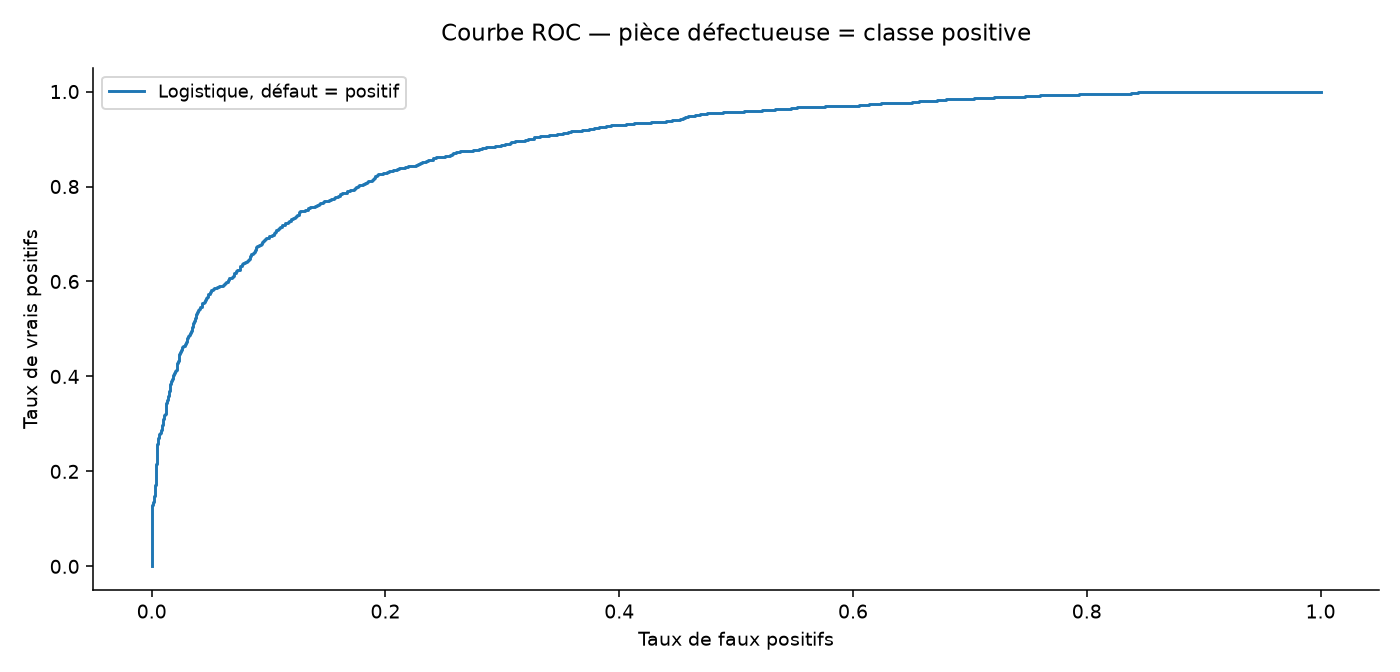

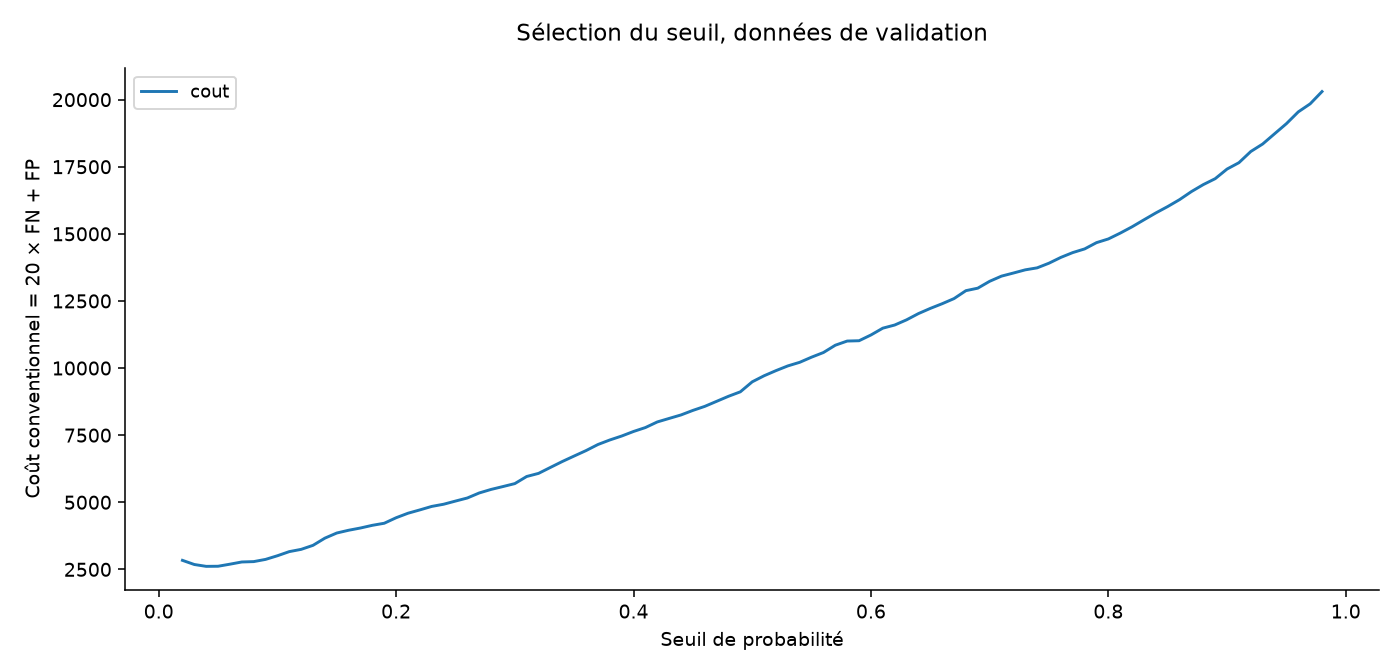

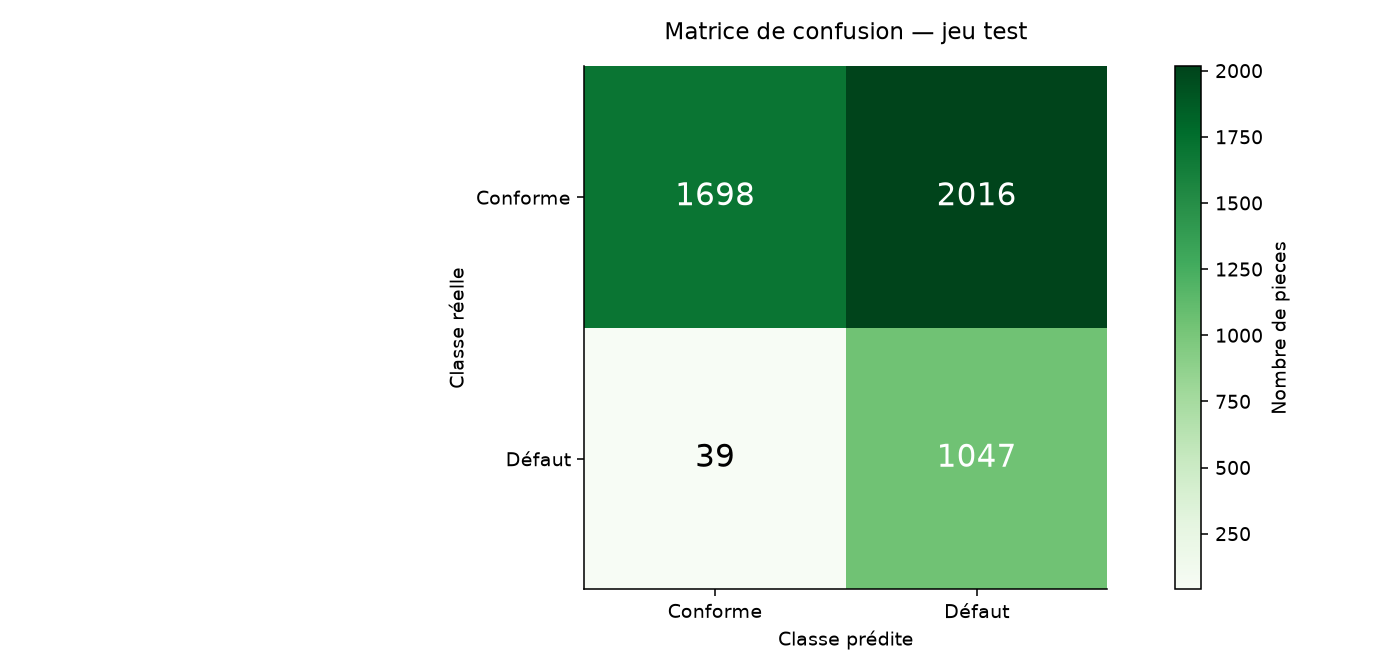

In [32]:
finish('QualiScan — détection et coût des erreurs', 'Détecter les pièces suspectes en maîtrisant les erreurs et la fuite entre lots.', {'pieces': len(v), 'train': len(fit), 'validation': len(valid), 'test': len(te), 'seuil_validation': t, 'cout_fn': 20, 'cout_fp': 1, 'roc_auc_test': roc_auc_score(Y.iloc[te], p), 'auc_ic95_bas': ci[0], 'auc_ic95_haut': ci[1], 'average_precision_test': average_precision_score(Y.iloc[te], p), 'precision_test': precision_score(Y.iloc[te], pred), 'recall_test': recall_score(Y.iloc[te], pred), 'f1_test': f1_score(Y.iloc[te], pred), 'brier_test': brier_score_loss(Y.iloc[te], p), 'faux_negatifs': int(fn), 'faux_positifs': int(fp), 'roc_auc_rf_test': roc_auc_score(Y.iloc[te], prf), 'ari_clustering_test': ari, 'rmse_regression_mm': rmse, 'rmse_baseline_mm': baseline, 'cv_auc_moyenne': cvres['test_roc_auc'].mean()}, {'seuils_validation': thresholds, 'predictions_test': outputs, 'cv': pd.DataFrame(cvres), 'matrice_confusion': pd.DataFrame(cm, columns=['Predit conforme', 'Prédit défaut']).assign(reel=['Conforme', 'Défaut'])}, [f'{len(fit)} apprentissage, {len(valid)} validation et {len(te)} test, sans lot commun.', f'Seuil sur validation : {t:.2f} ; AUC test {roc_auc_score(Y.iloc[te], p):.3f}, rappel {recall_score(Y.iloc[te], pred):.3f}.', f'Régression sans étiquette : RMSE {rmse:.3f} mm, baseline {baseline:.3f} mm.'], ['Conserver le test fermé lors du choix du seuil.', 'Soumettre les pièces suspectes à expertise humaine ; surveiller dérive et prévalence.'], ['Simulation physique, aucune capacité démontrée sur de vraies pièces.', 'Coût 20:1 conventionnel, à revoir selon risque métier.', 'Forêt évaluée séparément, pas de sélection après lecture du test.', 'Bootstrap par lot ; régression évaluée sur valeurs observées, hypothèse de manque aléatoire.'])

In [33]:
import pandas as pd, numpy as np
from sklearn.metrics import confusion_matrix

## Analyse approfondie et interprétation

Les calculs suivants relisent les CSV produits par ce notebook et les confrontent aux hypothèses métier. Les tableaux affichés sont limités à trente lignes ; les exports CSV restent complets.

In [34]:
r = Restitution()

In [35]:
m = r.m

In [36]:
p = r.read('analysis/predictions_test.csv')

In [37]:
spl = r.read('analysis/partition_lots.csv')

In [38]:
cv = r.read('analysis/cv.csv')

In [39]:
thresholds = r.read('analysis/seuils_validation.csv')

In [40]:
rows = []

In [41]:
for t in [m['seuil_validation'], 0.5]:
    tn, fp, fn, tp = confusion_matrix(p.reel_defaut, p.probabilite_defaut >= t, labels=[0, 1]).ravel()
    rows.append(dict(seuil=t, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp), cout=20 * int(fn) + int(fp), controles=int(tp + fp), rappel=tp / (tp + fn), precision=tp / (tp + fp)))

In [42]:
compare = pd.DataFrame(rows)

In [43]:
chosen = compare.iloc[0]

In [44]:
fpr = chosen.fp / (chosen.fp + chosen.tn)

In [45]:
tpr = chosen.rappel

In [46]:
sc = []

In [47]:
for prev in [0.01, 0.05, 0.1, float(p.reel_defaut.mean())]:
    tp = 1000 * prev * tpr
    fp = 1000 * (1 - prev) * fpr
    sc.append(dict(prevalence=prev, vrais_defauts_detectes=tp, fausses_alertes=fp, controles=tp + fp, precision_attendue=tp / (tp + fp)))

In [48]:
partitions = spl.groupby('split').agg(pieces=('piece_id', 'size'), lots=('lot_id', 'nunique')).reset_index()

In [49]:
gain = 1 - m['rmse_regression_mm'] / m['rmse_baseline_mm']

In [50]:
r.resume = [f"QualiScan conserve {m['pieces']} pièces fictives réparties par lots. L’apprentissage, la validation et le test n’ont aucun lot commun.", f"Le seuil {m['seuil_validation']:.2f} est choisi sur validation avec un coût d’erreur 20:1. Le test donne un rappel de {m['recall_test']:.1%} et une précision de {m['precision_test']:.1%}.", f"Le test contient {m['faux_negatifs']} défauts manqués et {m['faux_positifs']} fausses alertes. {int(chosen.controles)} contrôles humains sont requis sur {len(p)} pièces.", f"L’AUC vaut {m['roc_auc_test']:.3f} ; son intervalle bootstrap par lot est [{m['auc_ic95_bas']:.3f} ; {m['auc_ic95_haut']:.3f}]. Ces résultats portent uniquement sur la simulation."]

In [51]:
r.section('4. Séparer les lots et prévenir les fuites', ['Les mesures d’un même lot partagent une dérive de fabrication. Une séparation aléatoire des pièces aurait laissé le modèle retrouver cette dérive dans le test. Les lots sont donc séparés avant l’imputation, la standardisation et l’apprentissage.', 'L’imputation médiane ajoute un indicateur de valeur absente. Les transformations du pipeline sont ajustées uniquement sur l’apprentissage, y compris à l’intérieur des cinq plis de validation croisée. Les fichiers de modèles permettent de réappliquer le même traitement à de nouvelles mesures.'], [('Répartition des pièces et lots', partitions), ('Validation croisée par lots', cv)])

## 4. Séparer les lots et prévenir les fuites

Les mesures d’un même lot partagent une dérive de fabrication. Une séparation aléatoire des pièces aurait laissé le modèle retrouver cette dérive dans le test. Les lots sont donc séparés avant l’imputation, la standardisation et l’apprentissage.

L’imputation médiane ajoute un indicateur de valeur absente. Les transformations du pipeline sont ajustées uniquement sur l’apprentissage, y compris à l’intérieur des cinq plis de validation croisée. Les fichiers de modèles permettent de réappliquer le même traitement à de nouvelles mesures.

### Répartition des pièces et lots

        split  pieces  lots
0        test    4800    96
1       train   14400   288
2  validation    4780    96

### Validation croisée par lots

   fit_time  score_time  test_roc_auc  test_average_precision
0  0.022513    0.011565      0.902574                0.758415
1  0.021014    0.008978      0.892262                0.729499
2  0.021004    0.008998      0.901775                0.751400
3  0.022986    0.008993      0.906440                0.755365
4  0.019990    0.008991      0.894856                0.744442

In [52]:
r.section('5. Choisir un seuil selon le coût métier', [f"La validation minimise 20 × défauts manqués + fausses alertes. Le seuil retenu est {m['seuil_validation']:.2f}. Ce coût est une convention pédagogique, pas une perte financière mesurée.", f'Au seuil retenu, le coût conventionnel sur test atteint {int(chosen.cout)} unités. Le seuil 0,50 est présenté uniquement comme comparaison descriptive après gel du modèle : il ne sert pas à choisir une nouvelle configuration.', 'Un seuil faible augmente généralement le rappel et la file de contrôle. Une équipe incapable de traiter cette file devrait définir une contrainte de capacité sur validation, puis évaluer une seule fois la politique finale sur un nouveau test.'], [('Comparaison descriptive des seuils sur test', compare), ('Recherche du seuil sur validation', thresholds)])

## 5. Choisir un seuil selon le coût métier

La validation minimise 20 × défauts manqués + fausses alertes. Le seuil retenu est 0.04. Ce coût est une convention pédagogique, pas une perte financière mesurée.

Au seuil retenu, le coût conventionnel sur test atteint 2796 unités. Le seuil 0,50 est présenté uniquement comme comparaison descriptive après gel du modèle : il ne sert pas à choisir une nouvelle configuration.

Un seuil faible augmente généralement le rappel et la file de contrôle. Une équipe incapable de traiter cette file devrait définir une contrainte de capacité sur validation, puis évaluer une seule fois la politique finale sur un nouveau test.

### Comparaison descriptive des seuils sur test

   seuil    tn    fp   fn    tp  cout  controles    rappel  precision
0   0.04  1698  2016   39  1047  2796       3063  0.964088   0.341822
1   0.50  3531   183  462   624  9423        807  0.574586   0.773234

### Recherche du seuil sur validation

    seuil  cout   fn    fp    recall
0    0.02  2836   14  2556  0.986616
1    0.03  2681   22  2241  0.978967
2    0.04  2612   30  2012  0.971319
3    0.05  2616   39  1836  0.962715
4    0.06  2693   51  1673  0.951243
5    0.07  2775   63  1515  0.939771
6    0.08  2789   69  1409  0.934034
7    0.09  2871   78  1311  0.925430
8    0.10  3007   89  1227  0.914914
9    0.11  3161  100  1161  0.904398
10   0.12  3245  107  1105  0.897706
11   0.13  3395  117  1055  0.888145
12   0.14  3663  133  1003  0.872849
13   0.15  3854  146   934  0.860421
14   0.16  3957  154   877  0.852772
15   0.17  4041  160   841  0.847036
16   0.18  4141  167   801  0.840344
17   0.19  4218  173   758  0.834608
18   0.20  4423  185   723  0.823136
19   0.21  4591  195   691  0.813576
20   0.22  4715  203   655  0.805927
21   0.23  4845  211   625  0.798279
22   0.24  4926  216   606  0.793499
23   0.25  5044  223   584  0.786807
24   0.26  5159  230   559  0.780115
25   0.27  5346  241   526  0.769598
2

In [53]:
r.section('6. Évaluer le classement et les erreurs', [f"L’AUC ROC est {m['roc_auc_test']:.3f} et l’average precision {m['average_precision_test']:.3f}, à comparer à une prévalence test de {p.reel_defaut.mean():.1%}. L’AUC mesure le classement et ne décrit pas à elle seule le volume d’alertes au seuil opérationnel.", f"Le rappel {m['recall_test']:.1%} laisse {m['faux_negatifs']} défauts non détectés. La précision {m['precision_test']:.1%} signifie qu’une part importante des alertes concerne des pièces conformes. Le taux de fausses alertes parmi les conformes est de {fpr:.1%}.", 'Le bootstrap rééchantillonne les lots afin de préserver les dépendances entre pièces. L’intervalle ne couvre pas les changements futurs de machine, de matériau ou de prévalence. Une validation industrielle externe reste nécessaire.'])

## 6. Évaluer le classement et les erreurs

L’AUC ROC est 0.894 et l’average precision 0.757, à comparer à une prévalence test de 22.6%. L’AUC mesure le classement et ne décrit pas à elle seule le volume d’alertes au seuil opérationnel.

Le rappel 96.4% laisse 39 défauts non détectés. La précision 34.2% signifie qu’une part importante des alertes concerne des pièces conformes. Le taux de fausses alertes parmi les conformes est de 54.3%.

Le bootstrap rééchantillonne les lots afin de préserver les dépendances entre pièces. L’intervalle ne couvre pas les changements futurs de machine, de matériau ou de prévalence. Une validation industrielle externe reste nécessaire.

In [54]:
r.section('7. Anticiper la charge et un changement de prévalence', ['Les scénarios ci-dessous conservent hypothétiquement le rappel et le taux de fausses alertes du test. Ils appliquent la formule de Bayes sur 1 000 pièces. Ils illustrent qu’une faible prévalence peut fortement réduire la précision même avec le même modèle.', 'Ces scénarios ne sont pas des prévisions de production : une dérive des mesures peut aussi modifier les taux d’erreur. Il faut suivre simultanément prévalence, délais de contrôle, taux de confirmation et défauts découverts après libération.'], [('Scénarios de charge pour 1 000 pièces', pd.DataFrame(sc))])

## 7. Anticiper la charge et un changement de prévalence

Les scénarios ci-dessous conservent hypothétiquement le rappel et le taux de fausses alertes du test. Ils appliquent la formule de Bayes sur 1 000 pièces. Ils illustrent qu’une faible prévalence peut fortement réduire la précision même avec le même modèle.

Ces scénarios ne sont pas des prévisions de production : une dérive des mesures peut aussi modifier les taux d’erreur. Il faut suivre simultanément prévalence, délais de contrôle, taux de confirmation et défauts découverts après libération.

### Scénarios de charge pour 1 000 pièces

   prevalence  vrais_defauts_detectes  fausses_alertes   controles  \
0     0.01000                9.640884       537.382876  547.023760   
1     0.05000               48.204420       515.670436  563.874856   
2     0.10000               96.408840       488.529887  584.938727   
3     0.22625              218.125000       420.000000  638.125000   

   precision_attendue  
0            0.017624  
1            0.085488  
2            0.164819  
3            0.341822  

In [55]:
r.section('8. Situer les modèles complémentaires', [f"La forêt aléatoire est évaluée séparément et obtient une AUC de {m['roc_auc_rf_test']:.3f}. Le test ne doit pas devenir un outil de sélection répétée. Le clustering à deux groupes donne un ARI de {m['ari_clustering_test']:.3f} avec les étiquettes ; ses groupes ne remplacent donc pas une décision de conformité.", f"La régression de l’épaisseur manquante atteint une RMSE de {m['rmse_regression_mm']:.3f} mm contre {m['rmse_baseline_mm']:.3f} mm pour la médiane d’apprentissage, soit {gain:.1%} de réduction relative. Ce gain limité doit être confronté à la tolérance industrielle, absente du jeu fictif.", 'La régression n’utilise pas l’étiquette de défaut. Elle est évaluée sur les mesures observées dans les lots test ; extrapoler aux valeurs réellement manquantes suppose que leur mécanisme d’absence soit comparable.'])

## 8. Situer les modèles complémentaires

La forêt aléatoire est évaluée séparément et obtient une AUC de 0.882. Le test ne doit pas devenir un outil de sélection répétée. Le clustering à deux groupes donne un ARI de 0.231 avec les étiquettes ; ses groupes ne remplacent donc pas une décision de conformité.

La régression de l’épaisseur manquante atteint une RMSE de 0.549 mm contre 0.561 mm pour la médiane d’apprentissage, soit 2.2% de réduction relative. Ce gain limité doit être confronté à la tolérance industrielle, absente du jeu fictif.

La régression n’utilise pas l’étiquette de défaut. Elle est évaluée sur les mesures observées dans les lots test ; extrapoler aux valeurs réellement manquantes suppose que leur mécanisme d’absence soit comparable.

In [56]:
r.actions = [['1', 'Valider le coût', 'Faire confirmer le rapport 20:1 par la qualité', 'Coût documenté'], ['2', 'Dimensionner le contrôle', 'Comparer les alertes à la capacité disponible', 'File traitable'], ['3', 'Tester hors simulation', 'Évaluer de nouveaux lots industriels', 'Erreurs et intervalles publiés'], ['4', 'Surveiller la dérive', 'Suivre mesures, prévalence et confirmations', 'Seuils de surveillance définis']]

In [57]:
display(Markdown('## Synthèse argumentée\n\n' + '\n\n'.join(r.resume)))
if r.actions:
    display(pd.DataFrame(r.actions))

## Synthèse argumentée

QualiScan conserve 23980 pièces fictives réparties par lots. L’apprentissage, la validation et le test n’ont aucun lot commun.

Le seuil 0.04 est choisi sur validation avec un coût d’erreur 20:1. Le test donne un rappel de 96.4% et une précision de 34.2%.

Le test contient 39 défauts manqués et 2016 fausses alertes. 3063 contrôles humains sont requis sur 4800 pièces.

L’AUC vaut 0.894 ; son intervalle bootstrap par lot est [0.882 ; 0.908]. Ces résultats portent uniquement sur la simulation.

   0                         1  \
0  1           Valider le coût   
1  2  Dimensionner le contrôle   
2  3    Tester hors simulation   
3  4      Surveiller la dérive   

                                                2  \
0  Faire confirmer le rapport 20:1 par la qualité   
1   Comparer les alertes à la capacité disponible   
2            Évaluer de nouveaux lots industriels   
3     Suivre mesures, prévalence et confirmations   

                                3  
0                  Coût documenté  
1                  File traitable  
2  Erreurs et intervalles publiés  
3  Seuils de surveillance définis  

## Présentation PowerPoint

Cette cellule régénère une présentation modifiable à partir des résultats calculés. Les graphiques sont des images ; titres, textes et recommandations restent éditables dans PowerPoint.

In [58]:
# Créer un vrai fichier PowerPoint : titres et textes restent modifiables.
from pptx import Presentation
from pptx.util import Inches, Pt
from pptx.dml.color import RGBColor

presentation = Presentation()
presentation.core_properties.author = 'Imad Kaanane'
presentation.core_properties.last_modified_by = 'Imad Kaanane'
presentation.core_properties.title = ROOT.name
presentation.core_properties.subject = 'Analyse de données — projet personnel sur données synthétiques'
presentation.slide_width, presentation.slide_height = Inches(13.333), Inches(7.5)

def slide_text(title, lines):
    slide = presentation.slides.add_slide(presentation.slide_layouts[6])
    background = slide.background.fill
    background.solid()
    background.fore_color.rgb = RGBColor(245, 248, 251)
    heading = slide.shapes.add_textbox(Inches(.65), Inches(.4), Inches(12), Inches(.85)).text_frame
    heading.text = title
    heading.paragraphs[0].font.size = Pt(28 if len(title) < 65 else 22)
    heading.paragraphs[0].font.bold = True
    heading.paragraphs[0].font.color.rgb = RGBColor(20, 80, 95)
    body = slide.shapes.add_textbox(Inches(.7), Inches(1.5), Inches(11.9), Inches(5.2)).text_frame
    body.word_wrap = True
    for i, line in enumerate(lines):
        paragraph = body.paragraphs[0] if i == 0 else body.add_paragraph()
        paragraph.text = str(line)
        paragraph.font.size = Pt(20 if sum(len(str(x)) for x in lines) < 750 else 16)
        paragraph.space_after = Pt(18)
    footer = slide.shapes.add_textbox(Inches(.7), Inches(7.05), Inches(12), Inches(.25)).text_frame
    footer.text = 'Simulation pédagogique • données synthétiques • ' + str(len(presentation.slides))
    footer.paragraphs[0].font.size = Pt(10)
    return slide

slide_text(TITLE, [QUESTION, 'Analyse reproductible dans Jupyter ; présentation modifiable.', 'Données fictives : aucune mission réelle ni effet causal démontré.'])
slide_text('Question et méthode', [QUESTION, 'Contrôler les clés, les doublons et les valeurs invalides avant les agrégations.', 'Lire les unités et les hypothèses du notebook avant de comparer les résultats.'])
slide_text('Qualité des données', [str(row) for row in AUDIT] or ['Contrôles documentés dans le notebook.'])
items = [str(k).replace('_', ' ') + ' : ' + (f'{float(v):,.4f}' if isinstance(v, (float, np.floating)) else str(v)) for k, v in METRICS.items()]
for start in range(0, len(items), 7):
    slide_text('Indicateurs recalculés', items[start:start + 7])
slide_text('Résultats à retenir', FINDINGS)
for name, _ in FIGS:
    slide = slide_text(name.replace('_', ' ').capitalize(), [])
    slide.shapes.add_picture(str(REPORT / (name + '.png')), Inches(1), Inches(1.45), width=Inches(11.3), height=Inches(5.35))
for title, paragraphs in SECTIONS:
    slide_text(title, paragraphs[:2])
slide_text('Actions proposées', ACTIONS)
slide_text('Limites et prochaines étapes', LIMITS + ['Adapter les hypothèses et valider sur des données réelles avant toute décision.'])
target = ROOT / 'presentation' / 'soutenance.pptx'
target.parent.mkdir(exist_ok=True)
presentation.save(target)
summary = ['# ' + TITLE, '', QUESTION, '', '## Résultats'] + ['- ' + s for s in FINDINGS] + ['', '## Actions'] + ['- ' + s for s in ACTIONS] + ['', '## Limites'] + ['- ' + s for s in LIMITS]
(OUT / 'SYNTHESE.md').write_text('\n'.join(summary) + '\n', encoding='utf-8')
print('Présentation enregistrée :', target.relative_to(ROOT))


Présentation enregistrée : presentation\soutenance.pptx
